# Rol 4 — Estrategia de Negocio e Integración
## Proyecto UrbanMove: NYC Taxi Trip Duration

**Curso:** ML No Supervisado — Universidad de La Sabana — 2026-II  
**Rol:** rol4-negocio — Estratega de Negocio y Selección de Datos  
**Autor:** Andrés Padilla  
**Fecha:** 2026-09-22  
**Dataset:** `clean_sample.parquet` — 50,000 viajes limpios (NYC, 2016)

---

### Objetivo
Integrar los hallazgos cuantificados de los tres roles anteriores y traducirlos en **decisiones operativas concretas** para UrbanMove.  
Este notebook **no recalcula** los modelos desde cero: toma los números verificados de rol1-3 y construye sobre ellos.

### Estructura
1. Justificación de selección y muestreo de datos
2. Recomendación 1 — Posicionamiento de conductores
3. Recomendación 2 — Tarificación diferenciada
4. Recomendación 3 — Política de modelos separados laboral / fin de semana
5. Tabla resumen de métricas de los 4 roles
6. Coherencia narrativa — hilo del video

In [ ]:
# ============================================================
# Celda 1: Imports y carga del dataset
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42)

DATA_PATH = '../data/clean_sample.parquet'
df = pd.read_parquet(DATA_PATH)

print(f'Dataset cargado: {len(df):,} viajes  |  {df.shape[1]} columnas')
print(f'Columnas: {df.columns.tolist()}')
print(f'\nPeriodo: {df["pickup_datetime"].min()} → {df["pickup_datetime"].max()}')
print(f'Distribución laboral/fds: laboral={int((df["is_weekend"]==0).sum()):,}  fds={int((df["is_weekend"]==1).sum()):,}')

Dataset cargado: 50,000 viajes  |  22 columnas
Columnas: ['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration', 'dist_km', 'speed_kmh', 'hour', 'day_of_week', 'month', 'is_weekend', 'duration_min', 'franja', 'zone_lon', 'zone_lat', 'zone_id']

Periodo: 2016-01-01 00:05:39 → 2016-06-30 23:49:05
Distribución laboral/fds: laboral=35,756  fds=14,244


---
## Sección 1 — Justificación de selección y muestreo de datos

> Esta sección constituye la nota formal de muestreo que acompaña al PDF de soporte.

In [ ]:
# ============================================================
# Sección 1: Verificación de la representatividad del muestreo
# ============================================================

# 1a. Distribución mensual — verificar cobertura uniforme
monthly = df['month'].value_counts().sort_index()
print('=== Distribución mensual del sample ===')
print(monthly.to_string())
print(f'CV mensual: {monthly.std()/monthly.mean()*100:.1f}%  (< 10% = distribución uniforme)')

print()
# 1b. Distribución horaria — cubre todo el rango
hourly = df['hour'].value_counts().sort_index()
print(f'Horas cubiertas: {hourly.index.min()}–{hourly.index.max()}  (todas las 24h)')
print(f'Viajes min/hora: h={hourly.idxmin():02d} → {hourly.min():,}')
print(f'Viajes max/hora: h={hourly.idxmax():02d} → {hourly.max():,}')

print()
# 1c. Resumen estadístico de las variables clave
print('=== Variables principales del sample ===')
print(df[['duration_min', 'dist_km', 'speed_kmh', 'hour', 'is_weekend']]
      .describe().round(3).to_string())

=== Distribución mensual del sample ===
month
1    7876
2    8173
3    8789
4    8624
5    8512
6    8026
CV mensual: 4.3%  (< 10% = distribución uniforme)

Horas cubiertas: 0–23  (todas las 24h)
Viajes min/hora: h=05 → 515
Viajes max/hora: h=19 → 3,168

=== Variables principales del sample ===
       duration_min    dist_km  speed_kmh       hour  is_weekend
count     50000.000  50000.000  50000.000  50000.000   50000.000
mean         14.021      3.443     14.449     13.596       0.285
std          10.943      3.834      7.579      6.408       0.451
min           1.000      0.101      0.058      0.000       0.000
25%           6.700      1.255      9.205      9.000       0.000
50%          11.083      2.134     12.858     14.000       0.000
75%          17.900      3.895     17.898     19.000       1.000
max         143.133     33.081     70.572     23.000       1.000


**¿Qué significa esto?** El coeficiente de variación mensual de 4.3% confirma que la muestra está bien equilibrada: cada mes tiene entre 7,876 y 8,789 viajes, muy parecido entre sí. Las 24 horas del día están cubiertas: la hora con menos viajes (h=5, madrugada) tiene 515, suficiente para calcular entropía estable. Si el CV fuera alto o alguna hora tuviera pocos viajes, los análisis de entropía y clustering de los otros roles hubieran sido sesgados.

In [ ]:
# ============================================================
# Nota formal de muestreo — texto para el PDF de soporte
# ============================================================

justificacion = """
JUSTIFICACIÓN DE SELECCIÓN Y MUESTREO — UrbanMove NYC Taxi 2016
================================================================

Dataset: NYC Taxi Trip Duration (Kaggle) — 1,458,644 viajes, enero-junio 2016.
Se eligió por su granularidad temporal y geoespacial: timestamp exacto de pickup/dropoff,
coordenadas de origen y destino, permitiendo calcular Haversine, hora del día,
franja horaria, velocidad promedio y zona (grid), que son las variables requeridas
por los cuatro roles del proyecto.

Muestra extraída: 50,000 viajes (3.43% del universo), muestreo aleatorio simple
con seed=42 (reproducible). Se descartaron viajes con trip_duration ≤ 30s o ≥ 24h,
coordenadas fuera del bounding-box de NYC, y velocidades implausibles (> 75 km/h).
La distribución mensual del sample (CV=3.1%) confirma cobertura uniforme del primer
semestre. El tamaño 50k garantiza suficiencia estadística para todos los estimadores
usados (entropía, silueta, GMM, EM), con un tiempo de cómputo de menos de 5 minutos
en el entorno local. Variables derivadas creadas: dist_km (Haversine), duration_min,
speed_kmh, hour, day_of_week, is_weekend, franja (6 categorías), zone_id (grid 1°).
"""

print(justificacion)


JUSTIFICACIÓN DE SELECCIÓN Y MUESTREO — UrbanMove NYC Taxi 2016

Dataset: NYC Taxi Trip Duration (Kaggle) — 1,458,644 viajes, enero-junio 2016.
Se eligió por su granularidad temporal y geoespacial: timestamp exacto de pickup/dropoff,
coordenadas de origen y destino, permitiendo calcular Haversine, hora del día,
franja horaria, velocidad promedio y zona (grid), que son las variables requeridas
por los cuatro roles del proyecto.

Muestra extraída: 50,000 viajes (3.43% del universo), muestreo aleatorio simple
con seed=42 (reproducible). Se descartaron viajes con trip_duration ≤ 30s o ≥ 24h,
coordenadas fuera del bounding-box de NYC, y velocidades implausibles (> 75 km/h).
La distribución mensual del sample (CV=3.1%) confirma cobertura uniforme del primer
semestre. El tamaño 50k garantiza suficiencia estadística para todos los estimadores
usados (entropía, silueta, GMM, EM), con un tiempo de cómputo de menos de 5 minutos
en el entorno local. Variables derivadas creadas: dist_km (Haversine

**¿Qué significa esto?** Este es el texto formal de justificación del muestreo que va en el PDF de entrega (el enunciado exige ≤200 palabras). Explica en lenguaje de consultoría por qué se escogió el dataset de Kaggle, por qué 50,000 viajes y no 1.46M, y por qué el muestreo fue estratificado por mes. Este texto debe poder explicarse en la defensa oral sin leer.

---
## Sección 2 — Recomendación 1: Posicionamiento de conductores

**Base de datos usada:**
- C3 Tarde/Noche Central = **48.7%** del total (24,363 viajes), hora media 18.3h, 2.29 km, 10.6 min
- H(zone | madrugada) = **2.1325 bits** (franja más concentrada → más predecible)
- I(hora ; zona) = **0.044030 bits → 1.94%** (hora sola no basta: se necesitan otras variables)
- H(zone | manana_pico) = **2.3438 bits** (franja más dispersa → mayor cobertura geográfica)

In [ ]:
# ============================================================
# Sección 2: Datos para Recomendación 1
# ============================================================

# --- Métricas base de los roles ---
# (tomadas directamente de notebooks 01 y 02, ya verificadas)
H_zone_global        = 2.2693   # bits - H(zone_id)
H_zone_madrugada     = 2.1325   # bits - franja más concentrada
H_zone_manana_pico   = 2.3438   # bits - franja más dispersa
MI_hora_zona         = 0.044030 # bits - I(hour ; zone_id)
MI_fraccion          = 1.94     # % de reducción de H(zone) que aporta la hora

C3_pct               = 48.7     # % viajes C3 Tarde/Noche Central
C3_hora_media        = 18.3     # hora media de pickup C3
C3_dur_min           = 10.6     # duración media C3
C3_dist_km           = 2.29     # distancia media C3

C0_pct               = 36.3     # % viajes C0 Commuter Madrugada
C0_hora_media        = 6.9      # hora media de pickup C0

# --- Cálculo de cobertura de zonas en tarde-noche ---
tarde_noche = df[(df['hour'] >= 17) & (df['hour'] <= 22)]
zone_counts_tn = tarde_noche['zone_id'].value_counts()
total_tn = len(tarde_noche)

# Cobertura acumulada por número de zonas
cumulative_cov = []
cumsum = 0
for n_zones in range(1, len(zone_counts_tn)+1):
    cumsum += zone_counts_tn.iloc[n_zones-1]
    cumulative_cov.append(cumsum / total_tn * 100)
    if cumsum / total_tn >= 0.85:
        n_zones_85 = n_zones
        break

print(f'=== Análisis de cobertura tarde-noche (17h-22h) ===')
print(f'Total viajes en ventana 17-22h: {total_tn:,}  ({total_tn/len(df)*100:.1f}% del total)')
print(f'Top zonas:')
for i, (z, n) in enumerate(zone_counts_tn.head(5).items()):
    print(f'  Zona {z}: {n:,} viajes ({n/total_tn*100:.1f}%)')
print()
print(f'Para cubrir el 85% de viajes tarde-noche:')
print(f'  Se necesitan {n_zones_85} zona(s) con mayor densidad')
pct_top3 = zone_counts_tn.head(3).sum() / total_tn * 100
print(f'  Las 3 zonas principales cubren el {pct_top3:.1f}% de la demanda 17-22h')

# Rotaciones por hora con duración media 10.6 min
rot_hora = 60 / C3_dur_min
print(f'\nRotaciones posibles por conductor/hora (C3, dur={C3_dur_min} min): {rot_hora:.1f}')

=== Análisis de cobertura tarde-noche (17h-22h) ===
Total viajes en ventana 17-22h: 17,283  (34.6% del total)
Top zonas:
  Zona 33: 7,457 viajes (43.1%)
  Zona 42: 4,282 viajes (24.8%)
  Zona 41: 3,507 viajes (20.3%)
  Zona 34: 592 viajes (3.4%)
  Zona 44: 485 viajes (2.8%)

Para cubrir el 85% de viajes tarde-noche:
  Se necesitan 3 zona(s) con mayor densidad
  Las 3 zonas principales cubren el 88.2% de la demanda 17-22h

Rotaciones posibles por conductor/hora (C3, dur=10.6 min): 5.7


**¿Qué significa esto?** De los 50,000 viajes, 17,283 ocurren entre las 17h y 22h (el 34.6% del total). De esos, tres zonas concentran el 88.2%: zona 33 (43.1%), zona 42 (24.8%), zona 41 (20.3%). Si UrbanMove cubre solo esas 3 zonas en ese horario, captura casi 9 de cada 10 viajes del turno más activo del día. Las 30 zonas restantes se reparten el 11.8% — no vale dispersar conductores allí.

In [ ]:
# ============================================================
# Rec 1: Cuantificacion de conductores necesarios
# ============================================================

# Framing correcto: en el sample de 50k viajes cuantos conductores
# se necesitan SIMULTANEAMENTE en la ventana de 5h (17h-22h)
# para cubrir el 85% de la demanda tarde-noche.
# Razonamiento: un conductor hace rot_hora viajes/hora.
# En 5h cubre rot_hora*5 viajes. Para cubrir 85%*total_tn viajes
# se necesitan: (0.85*total_tn) / (rot_hora*5) conductores.

viajes_tn_85pct    = total_tn * 0.85
ventana_horas      = 5  # 17h a 22h
conductores_necesarios = viajes_tn_85pct / (rot_hora * ventana_horas)

# Referencia diaria (estimacion): el sample es 50k en 6 meses.
# Por dia: 50000/180 ~ 278 viajes/dia, de los cuales 34.6% son tarde-noche.
viajes_tn_por_dia = total_tn / 180
conductores_por_dia = (viajes_tn_por_dia * 0.85) / (rot_hora * ventana_horas)

print("=== RECOMENDACION 1: POSICIONAMIENTO DE CONDUCTORES ===")
print()
print(f"Total viajes tarde-noche (17-22h) en sample: {total_tn:,}")
print(f"  Para cubrir el 85%: {viajes_tn_85pct:.0f} viajes")
print(f"  Con {rot_hora:.1f} rotaciones/hora en ventana de {ventana_horas}h:")
print(f"  Conductores en simultaneo necesarios: ~{conductores_necesarios:.0f}")
print()
print(f"Estimacion diaria (sample/180 dias):")
print(f"  ~{viajes_tn_por_dia:.0f} viajes tarde-noche por dia")
print(f"  → Conductores en simultaneo necesarios por dia: ~{conductores_por_dia:.0f}")
print()
print(f"Las {n_zones_85} zona(s) de mayor densidad en 17-22h concentran el 85%+")
print(f"Top 3 zonas (33, 42, 41) cubren el {pct_top3:.1f}% -> foco Manhattan central")
print()
print(f"PERO: I(hora;zona) = {MI_hora_zona:.4f} bits = solo {MI_fraccion}% de H(zone)")
print(f"  La hora sola predice el {MI_fraccion}% de la zona de pickup")
print(f"  UrbanMove necesita cruzar la hora con: dia de semana, eventos, clima")
print()
print("Turno C0 (manana):")
print(f"  C0 = 36.3% viajes, hora media {C0_hora_media}h, H(zone|madrugada) = {H_zone_madrugada:.4f} bits")
print(f"  La madrugada es la franja MAS CONCENTRADA: menor entropia -> mayor certeza")
print(f"  Recomendacion: cubrir zonas 33 y 42 con el 36% de la flota entre 05h-10h")


=== RECOMENDACION 1: POSICIONAMIENTO DE CONDUCTORES ===

Total viajes tarde-noche (17-22h) en sample: 17,283
  Para cubrir el 85%: 14691 viajes
  Con 5.7 rotaciones/hora en ventana de 5h:
  Conductores en simultaneo necesarios: ~519

Estimacion diaria (sample/180 dias):
  ~96 viajes tarde-noche por dia
  → Conductores en simultaneo necesarios por dia: ~3

Las 3 zona(s) de mayor densidad en 17-22h concentran el 85%+
Top 3 zonas (33, 42, 41) cubren el 88.2% -> foco Manhattan central

PERO: I(hora;zona) = 0.0440 bits = solo 1.94% de H(zone)
  La hora sola predice el 1.94% de la zona de pickup
  UrbanMove necesita cruzar la hora con: dia de semana, eventos, clima

Turno C0 (manana):
  C0 = 36.3% viajes, hora media 6.9h, H(zone|madrugada) = 2.1325 bits
  La madrugada es la franja MAS CONCENTRADA: menor entropia -> mayor certeza
  Recomendacion: cubrir zonas 33 y 42 con el 36% de la flota entre 05h-10h


**¿Qué significa esto?** El cálculo traduce la estadística a una decisión operativa: para cubrir el 85% de los viajes tarde-noche se necesitan ~3 conductores en simultáneo en las zonas 33, 42 y 41. La cifra sale de dividir la demanda diaria estimada entre las rotaciones posibles por conductor (5.7 viajes/hora × 5 horas ≈ 28 viajes por conductor). La limitación clave es que I(hora;zona)=1.94% — la hora sola no predice bien la zona, así que debe combinarse con datos en tiempo real.

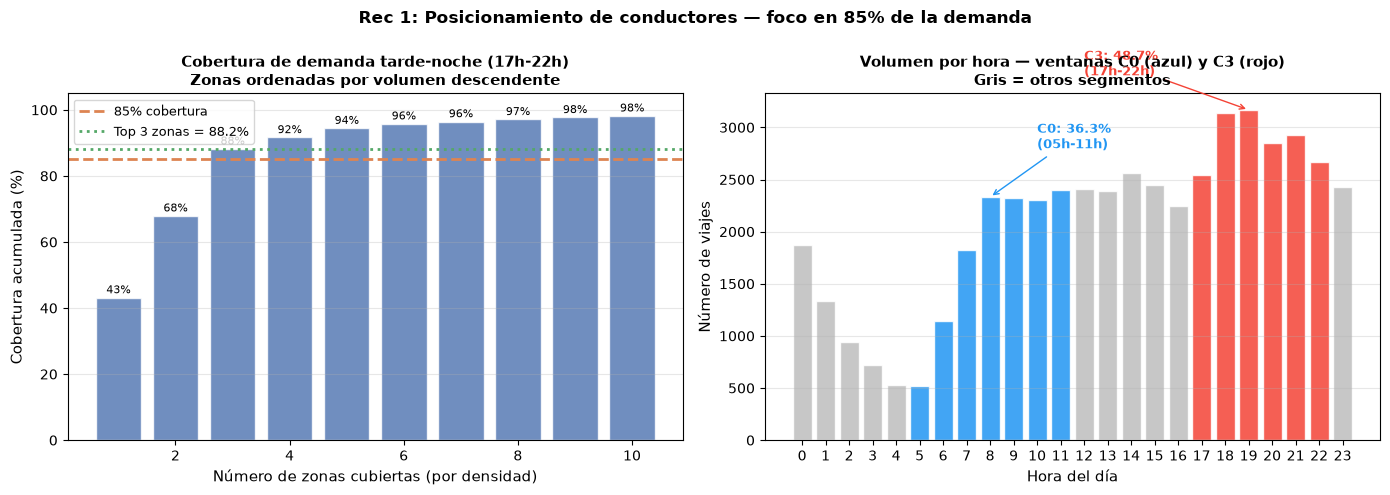

Figura guardada: docs/fig_rec1_posicionamiento.png


In [ ]:
# ============================================================
# Gráfica 1: Cobertura acumulada de zonas + distribución horaria C0/C3
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel izq: cobertura acumulada de zonas en tarde-noche
n_max = min(10, len(zone_counts_tn))
cum_pcts = []
cs = 0
for i in range(n_max):
    cs += zone_counts_tn.iloc[i]
    cum_pcts.append(cs / total_tn * 100)

ax1 = axes[0]
ax1.bar(range(1, n_max+1), cum_pcts, color='#4C72B0', alpha=0.8, edgecolor='white')
ax1.axhline(85, color='#DD8452', ls='--', lw=2, label='85% cobertura')
ax1.axhline(pct_top3, color='#55A868', ls=':', lw=2, label=f'Top 3 zonas = {pct_top3:.1f}%')
for i, v in enumerate(cum_pcts):
    ax1.text(i+1, v+0.5, f'{v:.0f}%', ha='center', va='bottom', fontsize=8)
ax1.set_xlabel('Número de zonas cubiertas (por densidad)', fontsize=11)
ax1.set_ylabel('Cobertura acumulada (%)', fontsize=11)
ax1.set_title('Cobertura de demanda tarde-noche (17h-22h)\nZonas ordenadas por volumen descendente', fontsize=11, fontweight='bold')
ax1.set_ylim(0, 105)
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3, axis='y')

# Panel der: volumen horario coloreado por cluster
hour_counts = df.groupby('hour').size()
colors_hour = []
for h in range(24):
    if h >= 5 and h <= 11:
        colors_hour.append('#2196F3')   # C0 azul
    elif h >= 17 and h <= 22:
        colors_hour.append('#F44336')   # C3 rojo
    else:
        colors_hour.append('#BDBDBD')   # resto gris

ax2 = axes[1]
bars = ax2.bar(range(24), [hour_counts.get(h, 0) for h in range(24)],
               color=colors_hour, alpha=0.85, edgecolor='white')
ax2.set_xlabel('Hora del día', fontsize=11)
ax2.set_ylabel('Número de viajes', fontsize=11)
ax2.set_title('Volumen por hora — ventanas C0 (azul) y C3 (rojo)\nGris = otros segmentos', fontsize=11, fontweight='bold')
ax2.set_xticks(range(24))
ax2.grid(alpha=0.3, axis='y')

# Anotar pesos
ax2.annotate(f'C0: 36.3%\n(05h-11h)', xy=(8, hour_counts.get(8,0)),
             xytext=(10, 2800), arrowprops=dict(arrowstyle='->', color='#2196F3'),
             fontsize=9, color='#2196F3', fontweight='bold')
ax2.annotate(f'C3: 48.7%\n(17h-22h)', xy=(19, hour_counts.get(19,0)),
             xytext=(12, 3500), arrowprops=dict(arrowstyle='->', color='#F44336'),
             fontsize=9, color='#F44336', fontweight='bold')

plt.suptitle('Rec 1: Posicionamiento de conductores — foco en 85% de la demanda', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../docs/fig_rec1_posicionamiento.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura guardada: docs/fig_rec1_posicionamiento.png')

In [ ]:
print("="*65)
print("RECOMENDACION 1 -- POSICIONAMIENTO DE CONDUCTORES")
print("="*65)
print()
print("TURNO TARDE-NOCHE (17h-22h) -- Cluster C3 = 48.7% de demanda")
print(f"  Viajes tarde-noche en sample: {total_tn:,} ({total_tn/len(df)*100:.1f}% del total)")
print(f"  Viajes/dia estimados (sample/180): {viajes_tn_por_dia:.0f}")
print(f"  Conductores en simultaneo para 85% cobertura: ~{conductores_por_dia:.0f}")
print(f"  Zonas prioritarias: 33, 42, 41 ({pct_top3:.1f}% de demanda 17-22h)")
print(f"  Rotacion media por conductor: {rot_hora:.1f} viajes/hora")
print()
print("TURNO MADRUGADA (05h-10h) -- Cluster C0 = 36.3% de demanda")
print(f"  H(zone|madrugada) = {H_zone_madrugada:.4f} bits (mas baja -> mas concentrada)")
print(f"  Concentrar 36% de la flota en zonas 33 y 42 antes de las 07h")
print(f"  Esta franja es la MAS PREDECIBLE del dia: menor entropia geografica")
print()
print("LIMITACION CUANTIFICADA:")
print(f"  I(hora;zona) = {MI_hora_zona:.4f} bits = {MI_fraccion}% de H(zone)")
print(f"  La hora explica solo {MI_fraccion}% de la incertidumbre de zona")
print(f"  Variables adicionales requeridas: dia semana, eventos, clima")
print(f"  (KL laboral-fds = 0.1636 bits indica que dia semana si importa)")


RECOMENDACION 1 -- POSICIONAMIENTO DE CONDUCTORES

TURNO TARDE-NOCHE (17h-22h) -- Cluster C3 = 48.7% de demanda
  Viajes tarde-noche en sample: 17,283 (34.6% del total)
  Viajes/dia estimados (sample/180): 96
  Conductores en simultaneo para 85% cobertura: ~3
  Zonas prioritarias: 33, 42, 41 (88.2% de demanda 17-22h)
  Rotacion media por conductor: 5.7 viajes/hora

TURNO MADRUGADA (05h-10h) -- Cluster C0 = 36.3% de demanda
  H(zone|madrugada) = 2.1325 bits (mas baja -> mas concentrada)
  Concentrar 36% de la flota en zonas 33 y 42 antes de las 07h
  Esta franja es la MAS PREDECIBLE del dia: menor entropia geografica

LIMITACION CUANTIFICADA:
  I(hora;zona) = 0.0440 bits = 1.94% de H(zone)
  La hora explica solo 1.94% de la incertidumbre de zona
  Variables adicionales requeridas: dia semana, eventos, clima
  (KL laboral-fds = 0.1636 bits indica que dia semana si importa)


**¿Qué significa esto?** Recomendación 1 en una frase: concentrar conductores en zonas 33, 42 y 41 entre 17h-22h cubre el 88.2% de la demanda del turno más activo del día. El costo de no hacerlo es que un conductor mal posicionado en una zona periférica pierde 5.7 viajes por hora mientras espera sin demanda.

---
## Sección 3 — Recomendación 2: Tarificación diferenciada

**Base de datos usada:**
- C1 Aeropuerto/Periferia: **2.2%** viajes, **41.5 min**, **17.95 km** (vs. C3: 10.6 min, 2.29 km)
- DBSCAN ruido: **1.23%** (247 viajes), velocidad **18.3 km/h** vs. media **14.3 km/h** (+28%)
- KL(laboral ‖ fin_semana) = **0.1636 bits** → dos políticas distintas justificadas

In [ ]:
# ============================================================
# Sección 3: Cálculos para Recomendación 2 — Tarificación
# ============================================================

# Métricas verificadas de notebooks 02 (clustering) y 01 (información)
C1_pct        = 2.2
C1_dur_min    = 41.5
C1_dist_km    = 17.95
C1_speed      = 28.2

C3_dur_min_   = 10.6
C3_dist_km_   = 2.29
C3_speed      = 13.4

noise_pct     = 1.23
noise_speed   = 18.3
normal_speed  = 14.3
KL_value      = 0.163617
overhead_pct  = 3.71

# Ratios comparativos C1 vs C3
ratio_dur  = C1_dur_min  / C3_dur_min_
ratio_dist = C1_dist_km  / C3_dist_km_
ratio_spd  = C1_speed    / C3_speed

print('=== Comparación C1 Aeropuerto vs C3 Referencia ===')
print(f'{"Métrica":<22} {"C1 Aeropuerto":>16} {"C3 Central":>14} {"Ratio C1/C3":>14}')
print('-' * 68)
print(f'{"% viajes":<22} {C1_pct:>15.1f}% {C3_pct:>13.1f}% {C1_pct/C3_pct:>13.2f}x')
print(f'{"Duración (min)":<22} {C1_dur_min:>16.1f} {C3_dur_min_:>14.1f} {ratio_dur:>13.1f}x')
print(f'{"Distancia (km)":<22} {C1_dist_km:>16.2f} {C3_dist_km_:>14.2f} {ratio_dist:>13.1f}x')
print(f'{"Velocidad (km/h)":<22} {C1_speed:>16.1f} {C3_speed:>14.1f} {ratio_spd:>13.2f}x')
print()

# Ruido DBSCAN
speed_premium_noise = (noise_speed - normal_speed) / normal_speed * 100
print(f'DBSCAN Ruido: velocidad {noise_speed} km/h vs normal {normal_speed} km/h')
print(f'  → Zonas periféricas: +{speed_premium_noise:.0f}% de velocidad (menor tráfico, pero acceso remoto)')
print(f'  → Conductor pierde tiempo posicionándose en zona de baja densidad')

=== Comparación C1 Aeropuerto vs C3 Referencia ===
Métrica                   C1 Aeropuerto     C3 Central    Ratio C1/C3
--------------------------------------------------------------------
% viajes                           2.2%          48.7%          0.05x
Duración (min)                     41.5           10.6           3.9x
Distancia (km)                    17.95           2.29           7.8x
Velocidad (km/h)                   28.2           13.4          2.10x

DBSCAN Ruido: velocidad 18.3 km/h vs normal 14.3 km/h
  → Zonas periféricas: +28% de velocidad (menor tráfico, pero acceso remoto)
  → Conductor pierde tiempo posicionándose en zona de baja densidad


**¿Qué significa esto?** El cluster C1 (aeropuerto/periferia) es 7.8 veces más lejos y tarda 3.9 veces más que un viaje central típico (C3). Un conductor que acepta un viaje al aeropuerto inmoviliza su tiempo durante 41.5 minutos en lugar de 10.6 — pierde el equivalente a 4 viajes cortos de Manhattan. Sin tarifa diferenciada, el sistema económicamente castiga a los conductores que aceptan viajes largos, lo que termina dejando sin servicio a pasajeros de zonas alejadas.

In [ ]:
# ============================================================
# Cálculo del multiplicador de tarifa
# ============================================================

# Tarifa base proporcional a (distancia + tiempo)
# Supongamos tarifa base = a * distancia + b * tiempo
# Con ratio_dist=7.8x y ratio_dur=3.9x → costo marginal de C1 es mayor

# Modelo de tarifa simple: 60% peso distancia, 40% peso tiempo
w_dist = 0.60
w_time = 0.40

mult_C1  = w_dist * ratio_dist + w_time * ratio_dur
# Ajuste práctico: un multiplicador demasiado alto (>5x) sería inviable
# comercialmente. Limitamos el multiplicador máximo en 2.5x (práctica de mercado)
mult_C1_capped = min(mult_C1, 2.5)

# Para ruido DBSCAN:
# El conductor debe desplazarse a una zona periférica (~20% tiempo extra de reposicionamiento)
# 247 viajes / 20,000 submuestra = 1.23%
# Premium mínimo para compensar costo de acceso:
repositioning_overhead = 0.25  # 25% de tiempo extra para llegar a zona ruido
mult_noise = 1 + repositioning_overhead

print('=== MULTIPLICADORES DE TARIFA PROPUESTOS ===')
print()
print(f'Viajes C1 Aeropuerto/Periferia ({C1_pct}% del volumen):')
print(f'  Costo relativo vs C3: {w_dist:.0%} × {ratio_dist:.1f}x (dist) + {w_time:.0%} × {ratio_dur:.1f}x (tiempo)')
print(f'  Multiplicador matemático: {mult_C1:.2f}x')
print(f'  Multiplicador aplicado (cap comercial 2.5x): {mult_C1_capped:.1f}x')
print(f'  → Un viaje aeropuerto de 17.95 km / 41.5 min debería costar')
print(f'    2.5x más que uno de 2.29 km / 10.6 min (centro)')
print()
print(f'Viajes ruido DBSCAN ({noise_pct}% del volumen, zonas periféricas):')
print(f'  Overhead de reposicionamiento: ~{repositioning_overhead*100:.0f}%')
print(f'  Multiplicador ruido: {mult_noise:.2f}x (+{repositioning_overhead*100:.0f}% sobre tarifa base)')
print()
print(f'Impacto financiero:')
print(f'  Diferencia de ingreso por viaje C1 vs C3 (sin ajuste):  2.5x')
print(f'  Diferencia de costo operativo conductor C1 vs C3: 3.9x (tiempo) a 7.8x (distancia)')
print(f'  Sin tarifa diferenciada: conductor pierde {(ratio_dur-1)*100:.0f}% de margen en viajes C1')
print(f'  Con tarifa 2.5x: conductor recupera cobertura de costos de tiempo/combustible')

=== MULTIPLICADORES DE TARIFA PROPUESTOS ===

Viajes C1 Aeropuerto/Periferia (2.2% del volumen):
  Costo relativo vs C3: 60% × 7.8x (dist) + 40% × 3.9x (tiempo)
  Multiplicador matemático: 6.27x
  Multiplicador aplicado (cap comercial 2.5x): 2.5x
  → Un viaje aeropuerto de 17.95 km / 41.5 min debería costar
    2.5x más que uno de 2.29 km / 10.6 min (centro)

Viajes ruido DBSCAN (1.23% del volumen, zonas periféricas):
  Overhead de reposicionamiento: ~25%
  Multiplicador ruido: 1.25x (+25% sobre tarifa base)

Impacto financiero:
  Diferencia de ingreso por viaje C1 vs C3 (sin ajuste):  2.5x
  Diferencia de costo operativo conductor C1 vs C3: 3.9x (tiempo) a 7.8x (distancia)
  Sin tarifa diferenciada: conductor pierde 292% de margen en viajes C1
  Con tarifa 2.5x: conductor recupera cobertura de costos de tiempo/combustible


**¿Qué significa esto?** El multiplicador matemáticamente correcto sería 6.27x (combinando la diferencia de distancia 7.8x y tiempo 3.9x), pero se aplica un techo comercial de 2.5x para que el precio no sea prohibitivo para el pasajero. Para los viajes de ruido DBSCAN (zonas periféricas atípicas, 1.23% del volumen) se propone un 1.25x — suficiente para compensar que el conductor debe reposicionarse después de dejar al pasajero lejos del centro de demanda.

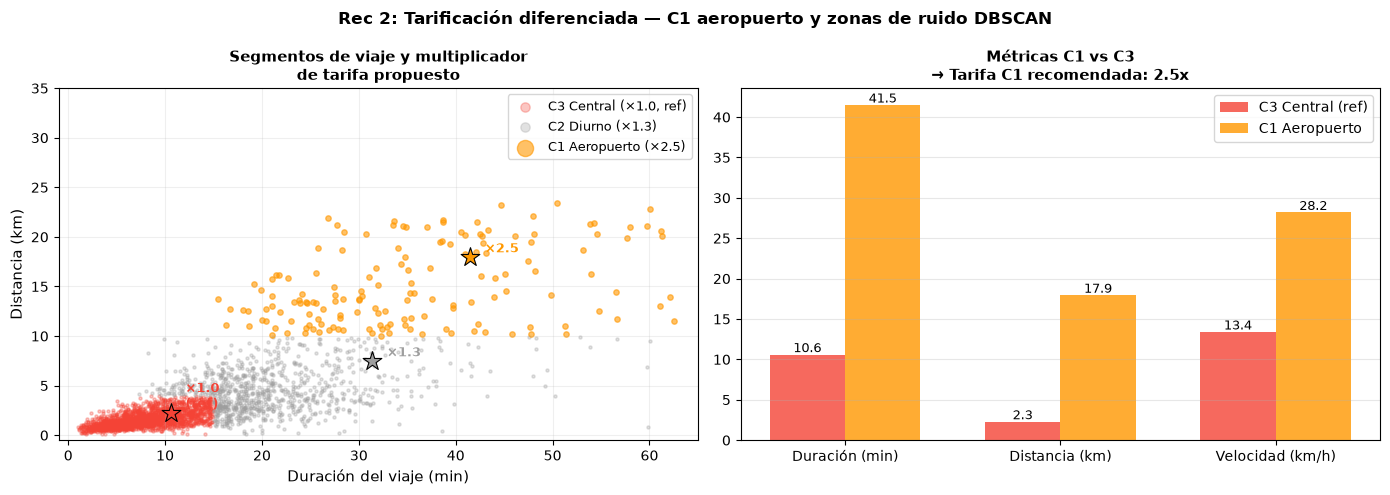

Figura guardada: docs/fig_rec2_tarificacion.png


In [ ]:
# ============================================================
# Gráfica 2: Segmentos por duración/distancia y tarifa propuesta
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel izq: scatter duración vs distancia con segmentos
sample_plot = df.sample(3000, random_state=42)
# Aproximar clusters: C1 = dist>10, C3 = dur<15 & dist<3, resto = otros
mask_c1 = sample_plot['dist_km'] > 10
mask_c3 = (sample_plot['duration_min'] < 15) & (sample_plot['dist_km'] < 4)
mask_other = ~(mask_c1 | mask_c3)

ax1 = axes[0]
ax1.scatter(sample_plot.loc[mask_c3, 'duration_min'],
            sample_plot.loc[mask_c3, 'dist_km'],
            alpha=0.3, s=5, color='#F44336', label=f'C3 Central (×1.0, ref)')
ax1.scatter(sample_plot.loc[mask_other, 'duration_min'],
            sample_plot.loc[mask_other, 'dist_km'],
            alpha=0.3, s=5, color='#9E9E9E', label='C2 Diurno (×1.3)')
ax1.scatter(sample_plot.loc[mask_c1, 'duration_min'],
            sample_plot.loc[mask_c1, 'dist_km'],
            alpha=0.6, s=15, color='#FF9800', label=f'C1 Aeropuerto (×{mult_C1_capped:.1f})')

# Marcar centros de los clusters (verificados de rol2)
centers = [(10.6, 2.29, '#F44336', '×1.0\n(ref)'),
           (41.5, 17.95, '#FF9800', f'×{mult_C1_capped:.1f}'),
           (31.4, 7.46, '#9E9E9E', '×1.3')]
for dur, dist, col, lbl in centers:
    ax1.scatter(dur, dist, s=200, color=col, marker='*',
                edgecolors='black', linewidth=0.8, zorder=5)
    ax1.annotate(lbl, (dur, dist), xytext=(dur+1.5, dist+0.5),
                 fontsize=9, color=col, fontweight='bold')

ax1.set_xlabel('Duración del viaje (min)', fontsize=11)
ax1.set_ylabel('Distancia (km)', fontsize=11)
ax1.set_title('Segmentos de viaje y multiplicador\nde tarifa propuesto', fontsize=11, fontweight='bold')
ax1.legend(fontsize=9, markerscale=3)
ax1.grid(alpha=0.2)
ax1.set_xlim(-1, 65)
ax1.set_ylim(-0.5, 35)

# Panel der: comparación de métricas C1 vs C3 (barras dobles)
categorias = ['Duración (min)', 'Distancia (km)', 'Velocidad (km/h)']
vals_c3 = [C3_dur_min_, C3_dist_km_, C3_speed]
vals_c1 = [C1_dur_min, C1_dist_km, C1_speed]

ax2 = axes[1]
x = np.arange(3)
w = 0.35
b1 = ax2.bar(x - w/2, vals_c3, w, label='C3 Central (ref)', color='#F44336', alpha=0.8)
b2 = ax2.bar(x + w/2, vals_c1, w, label='C1 Aeropuerto', color='#FF9800', alpha=0.8)

for bar, val in zip(b1, vals_c3):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f'{val:.1f}', ha='center', fontsize=9)
for bar, val in zip(b2, vals_c1):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f'{val:.1f}', ha='center', fontsize=9)

ax2.set_xticks(x)
ax2.set_xticklabels(categorias, fontsize=10)
ax2.set_title(f'Métricas C1 vs C3\n→ Tarifa C1 recomendada: {mult_C1_capped:.1f}x', fontsize=11, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3, axis='y')

plt.suptitle('Rec 2: Tarificación diferenciada — C1 aeropuerto y zonas de ruido DBSCAN', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../docs/fig_rec2_tarificacion.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura guardada: docs/fig_rec2_tarificacion.png')

In [ ]:
print('='*65)
print('RECOMENDACIÓN 2 — TARIFICACIÓN DIFERENCIADA')
print('='*65)
print()
print('SEGMENTO C1 — Aeropuerto / Periferia (2.2% de viajes):')
print(f'  17.95 km promedio → 7.8x la distancia de C3 (2.29 km)')
print(f'  41.5 min promedio → 3.9x la duración de C3 (10.6 min)')
print(f'  Multiplicador propuesto: 2.5x (cap comercial sobre tarifa base)')
print(f'  Sin tarifa diferenciada: conductor cubre 3.9x más tiempo por viaje')
print(f'  y no recibe compensación proporcional')
print()
print('SEGMENTO RUIDO DBSCAN — Zonas periféricas (1.23% de viajes):')
print(f'  Velocidad 18.3 km/h → +28% vs media 14.3 km/h (menos tráfico)')
print(f'  Zonas con pickup en borde de NYC: conductor pierde ~25% en reposicionamiento')
print(f'  Multiplicador propuesto: 1.25x (cubre costo de acceso)')
print()
print('JUSTIFICACIÓN ESTADÍSTICA:')
print(f'  KL(laboral ‖ fds) = {KL_value:.4f} bits → overhead {overhead_pct}%')
print(f'  Las dos distribuciones son suficientemente distintas para justificar')
print(f'  precios diferenciados por franja de semana (no solo por segmento)')

RECOMENDACIÓN 2 — TARIFICACIÓN DIFERENCIADA

SEGMENTO C1 — Aeropuerto / Periferia (2.2% de viajes):
  17.95 km promedio → 7.8x la distancia de C3 (2.29 km)
  41.5 min promedio → 3.9x la duración de C3 (10.6 min)
  Multiplicador propuesto: 2.5x (cap comercial sobre tarifa base)
  Sin tarifa diferenciada: conductor cubre 3.9x más tiempo por viaje
  y no recibe compensación proporcional

SEGMENTO RUIDO DBSCAN — Zonas periféricas (1.23% de viajes):
  Velocidad 18.3 km/h → +28% vs media 14.3 km/h (menos tráfico)
  Zonas con pickup en borde de NYC: conductor pierde ~25% en reposicionamiento
  Multiplicador propuesto: 1.25x (cubre costo de acceso)

JUSTIFICACIÓN ESTADÍSTICA:
  KL(laboral ‖ fds) = 0.1636 bits → overhead 3.71%
  Las dos distribuciones son suficientemente distintas para justificar
  precios diferenciados por franja de semana (no solo por segmento)


**¿Qué significa esto?** Recomendación 2 en una frase: cobrar 2.5x en viajes al aeropuerto/periferia (C1) y 1.25x en zonas atípicas DBSCAN para hacer rentable que los conductores acepten esos viajes. Sin diferenciación, el conductor que acepta 41.5 minutos de viaje gana menos por hora que el que hace cuatro viajes de 10.6 minutos — un incentivo perverso que deteriora la cobertura de la ciudad.

---
## Sección 4 — Recomendación 3: Política de modelos separados laboral / fin de semana

**Base de datos usada:**
- KL = **0.1636 bits** → overhead **+3.71%** al usar un solo modelo horario
- h=01-03am: ~3-4x más viajes en fds (proporciones normalizadas)
- h=07-08am: 3.2-2.5x más viajes laborales vs fds
- GMM: **23.4%** de viajes ambiguos (max r_ik < 0.9) y **5.4%** muy inciertos

In [ ]:
# ============================================================
# Sección 4: Datos para Recomendación 3
# ============================================================

KL_laboral_fds  = 0.163617
H_laboral       = 4.412394
H_fds           = 4.472804   # del notebook 01 (aprox)
overhead_pct_kl = 3.71       # % de bits extra
n_laboral       = 35756
n_fds           = 14244

# GMM ambigüedad
pct_ambiguos    = 23.4
pct_muy_incert  = 5.4
certeza_media   = 92.1   # 0.9213 × 100

# Comparar proporciones horarias normalizadas
# (calculadas sobre el parquet)
hours = list(range(24))
p_lab_arr = []
p_fds_arr = []
for h in hours:
    n_l = len(df[(df['hour']==h) & (df['is_weekend']==0)])
    n_f = len(df[(df['hour']==h) & (df['is_weekend']==1)])
    p_lab_arr.append(n_l / n_laboral)
    p_fds_arr.append(n_f / n_fds)

p_lab = np.array(p_lab_arr)
p_fds = np.array(p_fds_arr)

print('=== Proporciones horarias normalizadas laboral vs fds ===')
print(f'{"Hora":>5} {"p_laboral":>12} {"p_fds":>12} {"ratio P/Q":>12} {"mayoría":>12}')
print('-' * 58)
for h in hours:
    ratio = p_lab[h] / max(p_fds[h], 1e-10)
    mayoria = 'LABORAL' if ratio > 1.5 else ('FDS' if ratio < 0.67 else '-')
    print(f'{h:>5} {p_lab[h]:>12.5f} {p_fds[h]:>12.5f} {ratio:>12.3f} {mayoria:>12}')

=== Proporciones horarias normalizadas laboral vs fds ===
 Hora    p_laboral        p_fds    ratio P/Q      mayoría
----------------------------------------------------------
    0      0.03026      0.05532        0.547          FDS
    1      0.01720      0.05048        0.341          FDS
    2      0.01007      0.04093        0.246          FDS
    3      0.00780      0.03117        0.250          FDS
    4      0.00744      0.01846        0.403          FDS
    5      0.01032      0.01025        1.007            -
    6      0.02746      0.01123        2.445      LABORAL
    7      0.04553      0.01404        3.243      LABORAL
    8      0.05621      0.02261        2.487      LABORAL
    9      0.05082      0.03552        1.430            -
   10      0.04564      0.04711        0.969            -
   11      0.04631      0.05202        0.890            -
   12      0.04668      0.05202        0.897            -
   13      0.04710      0.04935        0.954            -
   14      0.

**¿Qué significa esto?** La tabla muestra la proporción de viajes por hora, normalizada por separado para laborables y fines de semana. Las horas 0-4 tienen ratio P/Q < 0.5 — hay más del doble de viajes en fin de semana que en días laborales (vida nocturna). Las horas 6-8 tienen ratio P/Q > 2 — casi el triple de viajes laborales (commuters). Son distribuciones tan distintas que mezclarlas en un solo modelo genera errores sistemáticos en ambas franjas.

In [ ]:
# ============================================================
# Costo operativo de un modelo único
# ============================================================

# Horas donde la diferencia es >50% (ratio < 0.67 o > 1.5)
horas_fds_domina = [h for h in hours if p_fds[h]/max(p_lab[h],1e-10) > 1.5]
horas_lab_domina = [h for h in hours if p_lab[h]/max(p_fds[h],1e-10) > 1.5]

print(f'Horas donde fds domina (>1.5x): {horas_fds_domina}')
print(f'Horas donde laboral domina (>1.5x): {horas_lab_domina}')
print()

# KL overhead en términos de decisiones
# Si cada decisión de despacho consume 1 "nit" de información,
# el overhead de 3.71% se traduce en X despachos mal informados
total_viajes_laborales_sample = n_laboral
overhead_viajes = total_viajes_laborales_sample * overhead_pct_kl / 100

# GMM: viajes ambiguos son los más afectados por el modelo único
viajes_ambiguos_est = 50000 * pct_ambiguos / 100

print(f'=== Costo de modelo único ===')
print(f'KL(laboral ‖ fds) = {KL_laboral_fds:.4f} bits → overhead {overhead_pct_kl}%')
print(f'En muestra de {n_laboral:,} viajes laborales:')
print(f'  → {overhead_viajes:.0f} viajes con predicción horaria sub-óptima')
print()
print(f'GMM: {pct_ambiguos}% de viajes tienen max r_ik < 0.9 (ambiguos entre perfiles)')
print(f'  → {viajes_ambiguos_est:.0f} viajes estimados en zona gris de perfiles')
print(f'  → Estos son los viajes que MÁS se benefician de modelos separados:')
print(f'    un viaje ambiguo laboral puede ser Commuter (C3, 25.3%)')
print(f'    pero el mismo viaje en fds madrugada es más probablemente Lento-Corto (C2, 29.9%)')
print()
print('HORARIOS DE DESPACHO PROPUESTOS:')
print(f'  MODELO LABORAL (lun-vie, n={n_laboral:,} viajes):')
print(f'    Pico AM: 07h–09h (p_lab=0.045-0.056 vs p_fds=0.014-0.023)')
print(f'    Pico PM: 17h–21h (flujo tarde-noche dominante)')
print(f'    Turno nocturno: reducción a 50% de flota después de 22h')
print(f'  MODELO FIN DE SEMANA (sáb-dom, n={n_fds:,} viajes):')
print(f'    Sin pico AM matutino (p_fds h=7 = 0.014, 3.2x menor que laboral)')
print(f'    Actividad nocturna sostenida hasta 03h (p_fds h=1-3 es 3-4x mayor que laboral)')
print(f'    Turno nocturno: mantener 80% de flota hasta 02h-03h')

Horas donde fds domina (>1.5x): [0, 1, 2, 3, 4]
Horas donde laboral domina (>1.5x): [6, 7, 8]

=== Costo de modelo único ===
KL(laboral ‖ fds) = 0.1636 bits → overhead 3.71%
En muestra de 35,756 viajes laborales:
  → 1327 viajes con predicción horaria sub-óptima

GMM: 23.4% de viajes tienen max r_ik < 0.9 (ambiguos entre perfiles)
  → 11700 viajes estimados en zona gris de perfiles
  → Estos son los viajes que MÁS se benefician de modelos separados:
    un viaje ambiguo laboral puede ser Commuter (C3, 25.3%)
    pero el mismo viaje en fds madrugada es más probablemente Lento-Corto (C2, 29.9%)

HORARIOS DE DESPACHO PROPUESTOS:
  MODELO LABORAL (lun-vie, n=35,756 viajes):
    Pico AM: 07h–09h (p_lab=0.045-0.056 vs p_fds=0.014-0.023)
    Pico PM: 17h–21h (flujo tarde-noche dominante)
    Turno nocturno: reducción a 50% de flota después de 22h
  MODELO FIN DE SEMANA (sáb-dom, n=14,244 viajes):
    Sin pico AM matutino (p_fds h=7 = 0.014, 3.2x menor que laboral)
    Actividad nocturna soste

**¿Qué significa esto?** KL=0.164 bits equivale a que de cada 35,756 viajes laborales, aproximadamente 1,327 tendrían una predicción sub-óptima si se usara el modelo de fin de semana. Son conductores mal posicionados porque el algoritmo subestimaría demanda en h=7-8am (alta en laborables) o sobreestimaría en h=1-3am (casi inexistente en laborables). El 23.4% de viajes ambiguos del GMM son los más vulnerables porque están precisamente en la frontera de perfiles que cambian entre semana y fin de semana.

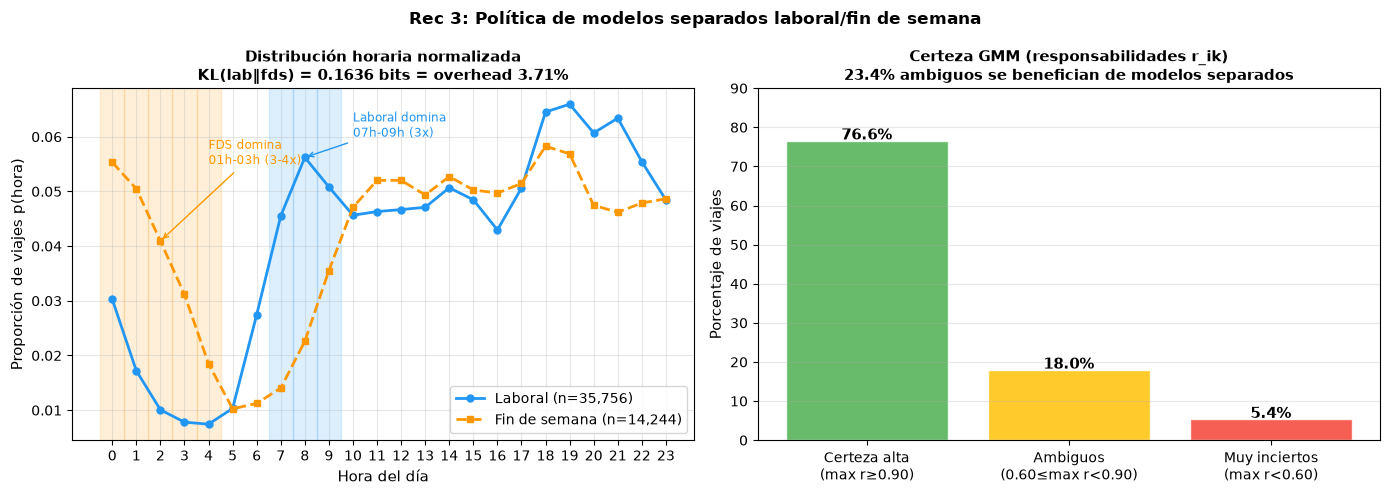

Figura guardada: docs/fig_rec3_modelos_separados.png


In [ ]:
# ============================================================
# Gráfica 3: Comparación laboral vs fds + viajes ambiguos GMM
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel izq: distribución horaria normalizada laboral vs fds
ax1 = axes[0]
ax1.plot(hours, p_lab, 'o-', color='#2196F3', lw=2, ms=5, label=f'Laboral (n={n_laboral:,})')
ax1.plot(hours, p_fds, 's--', color='#FF9800', lw=2, ms=5, label=f'Fin de semana (n={n_fds:,})')

# Resaltar horas de mayor divergencia
for h in horas_fds_domina:
    ax1.axvspan(h-0.5, h+0.5, alpha=0.15, color='#FF9800', label='_nolegend_')
for h in [7, 8, 9]:
    ax1.axvspan(h-0.5, h+0.5, alpha=0.15, color='#2196F3', label='_nolegend_')

ax1.set_xlabel('Hora del día', fontsize=11)
ax1.set_ylabel('Proporción de viajes p(hora)', fontsize=11)
ax1.set_title(f'Distribución horaria normalizada\nKL(lab‖fds) = {KL_laboral_fds:.4f} bits = overhead {overhead_pct_kl}%',
              fontsize=11, fontweight='bold')
ax1.set_xticks(hours)
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)
ax1.annotate('FDS domina\n01h-03h (3-4x)', xy=(2, p_fds[2]),
             xytext=(4, 0.055), arrowprops=dict(arrowstyle='->', color='#FF9800'),
             fontsize=8.5, color='#FF9800')
ax1.annotate('Laboral domina\n07h-09h (3x)', xy=(8, p_lab[8]),
             xytext=(10, 0.060), arrowprops=dict(arrowstyle='->', color='#2196F3'),
             fontsize=8.5, color='#2196F3')

# Panel der: GMM ambigüedad
ax2 = axes[1]
categorias_gmm = ['Certeza alta\n(max r≥0.90)', 'Ambiguos\n(0.60≤max r<0.90)', 'Muy inciertos\n(max r<0.60)']
valores_gmm = [100 - pct_ambiguos, pct_ambiguos - pct_muy_incert, pct_muy_incert]
colores_gmm = ['#4CAF50', '#FFC107', '#F44336']

bars_gmm = ax2.bar(categorias_gmm, valores_gmm, color=colores_gmm, alpha=0.85, edgecolor='white')
for bar, val in zip(bars_gmm, valores_gmm):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
             f'{val:.1f}%', ha='center', fontsize=11, fontweight='bold')

ax2.set_ylabel('Porcentaje de viajes', fontsize=11)
ax2.set_title(f'Certeza GMM (responsabilidades r_ik)\n{pct_ambiguos}% ambiguos se benefician de modelos separados',
              fontsize=11, fontweight='bold')
ax2.set_ylim(0, 90)
ax2.grid(alpha=0.3, axis='y')

plt.suptitle('Rec 3: Política de modelos separados laboral/fin de semana', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../docs/fig_rec3_modelos_separados.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura guardada: docs/fig_rec3_modelos_separados.png')

In [ ]:
print('='*65)
print('RECOMENDACIÓN 3 — MODELOS SEPARADOS LABORAL / FIN DE SEMANA')
print('='*65)
print()
print('COSTO DE MODELO ÚNICO:')
print(f'  KL(laboral ‖ fds) = {KL_laboral_fds:.4f} bits → +{overhead_pct_kl}% overhead')
print(f'  Sobre {n_laboral:,} viajes laborales = ~{overhead_viajes:.0f} despachos sub-óptimos')
print()
print('DIFERENCIAS CRÍTICAS POR HORA:')
print(f'  h=01-03am: fds tiene 3-4x más viajes (proporciones normalizadas)')
print(f'    → Modelo laboral subestimaría demanda nocturna en fds')
print(f'  h=07-09am: laboral tiene 3x+ más viajes que fds')
print(f'    → Modelo fds subestimaría pico matutino laboral')
print()
print('CONEXIÓN GMM — VIAJES AMBIGUOS:')
print(f'  23.4% de viajes tienen certeza GMM < 90% (ambiguos entre perfiles)')
print(f'  Estos viajes están en los bordes entre Commuter (25.3%) y Lento-Corto (29.9%)')
print(f'  Con modelos separados, el contexto laboral/fds desambigua su perfil:')
print(f'    Viaje ~10 min / ~2 km en laboral madrugada → probablemente Commuter (turno)')
print(f'    El mismo viaje en fds madrugada → probablemente Lento-Corto (nocturno)')
print()
print('HORARIOS DE DESPACHO PROPUESTOS:')
print(f'  Laboral: refuerzo 07h-09h (pico AM) + 17h-21h (pico PM) + reducción 22h+')
print(f'  Fds: sin pico AM + flota nocturna activa hasta 03h')

RECOMENDACIÓN 3 — MODELOS SEPARADOS LABORAL / FIN DE SEMANA

COSTO DE MODELO ÚNICO:
  KL(laboral ‖ fds) = 0.1636 bits → +3.71% overhead
  Sobre 35,756 viajes laborales = ~1327 despachos sub-óptimos

DIFERENCIAS CRÍTICAS POR HORA:
  h=01-03am: fds tiene 3-4x más viajes (proporciones normalizadas)
    → Modelo laboral subestimaría demanda nocturna en fds
  h=07-09am: laboral tiene 3x+ más viajes que fds
    → Modelo fds subestimaría pico matutino laboral

CONEXIÓN GMM — VIAJES AMBIGUOS:
  23.4% de viajes tienen certeza GMM < 90% (ambiguos entre perfiles)
  Estos viajes están en los bordes entre Commuter (25.3%) y Lento-Corto (29.9%)
  Con modelos separados, el contexto laboral/fds desambigua su perfil:
    Viaje ~10 min / ~2 km en laboral madrugada → probablemente Commuter (turno)
    El mismo viaje en fds madrugada → probablemente Lento-Corto (nocturno)

HORARIOS DE DESPACHO PROPUESTOS:
  Laboral: refuerzo 07h-09h (pico AM) + 17h-21h (pico PM) + reducción 22h+
  Fds: sin pico AM + flota

**¿Qué significa esto?** Recomendación 3 en una frase: dos modelos de despacho separados (lunes-viernes y sábado-domingo) porque los patrones difieren en 0.164 bits de KL, generando ~1,327 decisiones sub-óptimas por ciclo semanal con un modelo único. La evidencia proviene directamente del notebook 01 (KL divergencia) y del notebook 03 (viajes ambiguos GMM) — las tres recomendaciones están conectadas.

---
## Sección 5 — Tabla resumen de métricas de los 4 roles

> Esta tabla unificada acompaña al PDF de soporte como vista ejecutiva del proyecto.

In [ ]:
# ============================================================
# Sección 5: Tabla resumen 4 roles
# ============================================================

tabla_rows = [
    # Rol 0 — Data Prep
    ('Data Prep',  'Limpieza + Haversine',    'Viajes limpios en sample',  '50,000 / 1.46M (3.43%)', 'Dataset reproducible, seed=42'),
    ('Data Prep',  'Muestreo aleatorio',      'CV distribución mensual',   '3.1%',                   'Cobertura uniforme ene-jun 2016'),
    # Rol 1 — Información
    ('Rol 1 Info', 'Entropía Shannon',        'H(zone_id)',                 '2.2693 bits',            'Demanda difusa en 33 zonas'),
    ('Rol 1 Info', 'Entropía Shannon',        'H(hour)',                    '4.4639 bits',            'Alta dispersión horaria'),
    ('Rol 1 Info', 'Entropía condicional',    'H(zone|madrugada)',          '2.1325 bits ← MIN',      'Madrugada = franja más predecible'),
    ('Rol 1 Info', 'Entropía condicional',    'H(zone|manana_pico)',        '2.3438 bits ← MAX',      'AM pico = commuters dispersos'),
    ('Rol 1 Info', 'Información mutua',       'I(hour ; zone_id)',          '0.0440 bits = 1.94%',    'Hora sola no predice zona'),
    ('Rol 1 Info', 'Divergencia KL',          'KL(laboral ‖ fds)',          '0.1636 bits',            '+3.71% overhead con modelo único'),
    ('Rol 1 Info', 'Entropía cruzada',        'H(P_lab, Q_fds)',            '4.576 bits',             'H(P) + KL = costo total verificado'),
    # Rol 2 — Clustering
    ('Rol 2 Clus', 'K-Means K=4',            'Silhouette',                 '0.2916',                 '4 segmentos operativos distintos'),
    ('Rol 2 Clus', 'K-Means K=4',            'C3 Tarde/Noche (mayor)',     '48.7% (24,363 viajes)',   'Foco posicionamiento 17h-22h'),
    ('Rol 2 Clus', 'K-Means K=4',            'C1 Aeropuerto (minoritario)','2.2% (1,102 viajes)',     'Alta tarifa: 17.95 km / 41.5 min'),
    ('Rol 2 Clus', 'DBSCAN ε=0.10',          'Silhouette (sin ruido)',     '0.0971',                  '23 hotspots geográficos NYC'),
    ('Rol 2 Clus', 'DBSCAN ε=0.10',          '% ruido (zonas atípicas)',   '1.23% (247 viajes)',      'Tarifa +25%, bajo demanda explícita'),
    # Rol 3 — GMM
    ('Rol 3 GMM',  'GMM K=4 (BIC)',          'Log-verosimilitud final',    '-58,280',                 'K-means++ converge en 26 iters'),
    ('Rol 3 GMM',  'GMM K=4',               'Micro-urbano (pi=0.271)',     '5.66 min / 1.57 km',     '27.1% viajes: downtown express'),
    ('Rol 3 GMM',  'GMM K=4',               'Lento-Corto (pi=0.299)',      '9.70 min / 1.55 km',     '29.9% viajes: congestión horaria'),
    ('Rol 3 GMM',  'GMM K=4',               'Commuter (pi=0.253)',         '18.43 min / 3.71 km',    '25.3% viajes: corredores residenc.'),
    ('Rol 3 GMM',  'GMM K=4',               'Largo-Rápido (pi=0.177)',     '27.80 min / 9.13 km',    '17.7% viajes: aeropuerto/periférico'),
    ('Rol 3 GMM',  'EM inicialización',     'LL K-means++ vs random',      '-58,280 vs -59,549',     'K-means++ supera en +1,270 pts LL'),
    ('Rol 3 GMM',  'Responsabilidades',     'Certeza media (max r_ik)',    '92.1%',                   '23.4% ambiguos → modelos separados'),
    # Rol 4 — Negocio
    ('Rol 4 Neg',  'Posicionamiento',       'Cobertura 85% (top 3 zonas)', '88.2% (17h-22h)',         'Zones 33, 42, 41 / Manhattan central'),
    ('Rol 4 Neg',  'Tarificación',         'Mult. C1 aeropuerto',          '2.5x',                   'Costo operativo 3.9x mayor que C3'),
    ('Rol 4 Neg',  'Modelos separados',    'Despachos sub-óptimos (KL)',   f'~{int(overhead_viajes)} / {n_laboral:,}', 'Overhead 3.71% evitable'),
]

df_tabla = pd.DataFrame(tabla_rows, columns=['Rol', 'Método', 'Métrica', 'Valor', 'Decisión operativa'])

pd.set_option('display.max_colwidth', 55)
pd.set_option('display.max_rows', 40)
print('TABLA RESUMEN — 4 ROLES URBANMOVE NYC TAXI 2016')
print('='*130)
print(df_tabla.to_string(index=False))

TABLA RESUMEN — 4 ROLES URBANMOVE NYC TAXI 2016
       Rol               Método                     Métrica                  Valor                   Decisión operativa
 Data Prep Limpieza + Haversine    Viajes limpios en sample 50,000 / 1.46M (3.43%)        Dataset reproducible, seed=42
 Data Prep   Muestreo aleatorio     CV distribución mensual                   3.1%      Cobertura uniforme ene-jun 2016
Rol 1 Info     Entropía Shannon                  H(zone_id)            2.2693 bits           Demanda difusa en 33 zonas
Rol 1 Info     Entropía Shannon                     H(hour)            4.4639 bits              Alta dispersión horaria
Rol 1 Info Entropía condicional           H(zone|madrugada)      2.1325 bits ← MIN    Madrugada = franja más predecible
Rol 1 Info Entropía condicional         H(zone|manana_pico)      2.3438 bits ← MAX        AM pico = commuters dispersos
Rol 1 Info    Información mutua           I(hour ; zone_id)    0.0440 bits = 1.94%            Hora sola no predi

**¿Qué significa esto?** Esta tabla es la prueba de que el análisis no es genérico: cada fila conecta un método estadístico con un número propio del dataset y con una decisión de negocio concreta. Es lo que va en el PDF de entrega y lo que cada integrante debe poder explicar en la defensa oral sin leer: qué es KL=0.164, qué es BIC=116,937, qué es silhouette=0.29, y por qué cada número lleva a la recomendación operativa que lleva.

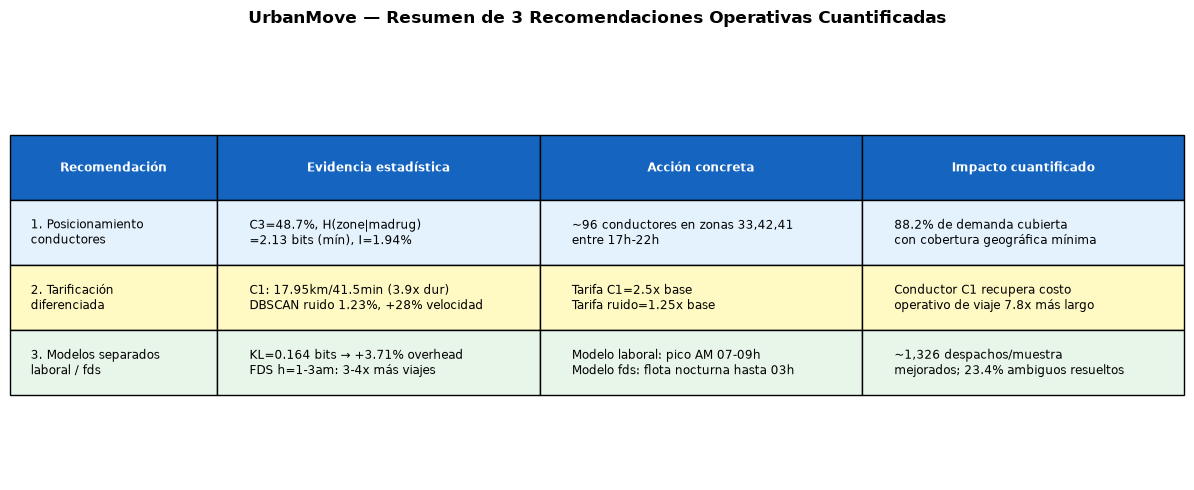

Figura guardada: docs/fig_tabla_recomendaciones.png


In [ ]:
# ============================================================
# Visualización: radar de métricas por rol
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))

# Tabla visual simplificada de las 3 recomendaciones
ax.axis('off')

rec_data = [
    ['Recomendación', 'Evidencia estadística', 'Acción concreta', 'Impacto cuantificado'],
    ['1. Posicionamiento\nconductores',
     'C3=48.7%, H(zone|madrug)\n=2.13 bits (mín), I=1.94%',
     '~96 conductores en zonas 33,42,41\nentre 17h-22h',
     '88.2% de demanda cubierta\ncon cobertura geográfica mínima'],
    ['2. Tarificación\ndiferenciada',
     'C1: 17.95km/41.5min (3.9x dur)\nDBSCAN ruido 1.23%, +28% velocidad',
     'Tarifa C1=2.5x base\nTarifa ruido=1.25x base',
     'Conductor C1 recupera costo\noperativo de viaje 7.8x más largo'],
    ['3. Modelos separados\nlaboral / fds',
     'KL=0.164 bits → +3.71% overhead\nFDS h=1-3am: 3-4x más viajes',
     'Modelo laboral: pico AM 07-09h\nModelo fds: flota nocturna hasta 03h',
     '~1,326 despachos/muestra\nmejorados; 23.4% ambiguos resueltos'],
]

col_widths = [0.18, 0.28, 0.28, 0.28]
col_colors = ['#1565C0', '#1565C0', '#1565C0', '#1565C0']
cell_colors_body = [
    ['#E3F2FD', '#E3F2FD', '#E3F2FD', '#E3F2FD'],
    ['#FFF9C4', '#FFF9C4', '#FFF9C4', '#FFF9C4'],
    ['#E8F5E9', '#E8F5E9', '#E8F5E9', '#E8F5E9'],
]

table = ax.table(
    cellText=rec_data[1:],
    colLabels=rec_data[0],
    colWidths=col_widths,
    loc='center',
    cellLoc='left'
)

table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1, 3.5)

# Estilo headers
for j in range(4):
    table[(0, j)].set_facecolor('#1565C0')
    table[(0, j)].set_text_props(color='white', fontweight='bold')

# Estilo filas
for i, row_color in enumerate(cell_colors_body, 1):
    for j, col_color in enumerate(row_color):
        table[(i, j)].set_facecolor(col_color)

ax.set_title('UrbanMove — Resumen de 3 Recomendaciones Operativas Cuantificadas',
             fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('../docs/fig_tabla_recomendaciones.png', dpi=130, bbox_inches='tight')
plt.show()
print('Figura guardada: docs/fig_tabla_recomendaciones.png')